In [1]:
import sys
import os

sys.path.append(os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from statistics import mean, median, variance, stdev

from src.population import (
    DistrictPopulation,
    LinearTrendForecaster,
    CAGRForecaster,
    FibonacciForecaster,
    mae,
    rmse,
    mape,
)

np.random.seed(42)
print("Setup complete")

Setup complete


In [2]:
years = list(range(2015, 2025))

data = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [320, 330, 345, 360, 375, 390, 410, 430, 455, 480],
    "Mbarara": [280, 295, 310, 325, 345, 365, 385, 405, 430, 455],
    "Mbale":   [250, 260, 272, 285, 298, 312, 327, 342, 358, 375],
}

districts = {name: DistrictPopulation(name, years, vals) for name, vals in data.items()}
for d in districts.values():
    print(d)

DistrictPopulation(name='Kampala', years=2015-2024, n=10)
DistrictPopulation(name='Wakiso', years=2015-2024, n=10)
DistrictPopulation(name='Gulu', years=2015-2024, n=10)
DistrictPopulation(name='Mbarara', years=2015-2024, n=10)
DistrictPopulation(name='Mbale', years=2015-2024, n=10)


In [3]:
for name, d in districts.items():
    p = d.populations
    print(f"\n{name}")
    print(f"  statistics.mean    = {mean(p):.2f}    np.mean    = {np.mean(p):.2f}")
    print(f"  statistics.median  = {median(p):.2f}    np.median  = {np.median(p):.2f}")
    print(f"  statistics.variance= {variance(p):.2f}    np.var     = {np.var(p):.2f}")
    print(f"  statistics.stdev   = {stdev(p):.2f}    np.std     = {np.std(p):.2f}")


Kampala
  statistics.mean    = 1477.00    np.mean    = 1477.00
  statistics.median  = 1460.00    np.median  = 1460.00
  statistics.variance= 42601.11    np.var     = 38341.00
  statistics.stdev   = 206.40    np.std     = 195.81

Wakiso
  statistics.mean    = 1280.00    np.mean    = 1280.00
  statistics.median  = 1260.00    np.median  = 1260.00
  statistics.variance= 60066.67    np.var     = 54060.00
  statistics.stdev   = 245.09    np.std     = 232.51

Gulu
  statistics.mean    = 389.50    np.mean    = 389.50
  statistics.median  = 382.50    np.median  = 382.50
  statistics.variance= 2885.83    np.var     = 2597.25
  statistics.stdev   = 53.72    np.std     = 50.96

Mbarara
  statistics.mean    = 359.50    np.mean    = 359.50
  statistics.median  = 355.00    np.median  = 355.00
  statistics.variance= 3463.61    np.var     = 3117.25
  statistics.stdev   = 58.85    np.std     = 55.83

Mbale
  statistics.mean    = 307.90    np.mean    = 307.90
  statistics.median  = 305.00    np.median  

### Why `statistics.variance` ≠ `np.var`

`statistics.variance` computes the **sample** variance, dividing the sum of squared
deviations by `n − 1` (Bessel's correction). `np.var` computes the **population**
variance by default, dividing by `n`. For our 10-year series, the ratio is
`10/9 ≈ 1.111`, so `statistics.variance` is about 11 % larger than `np.var`.

To make NumPy match `statistics`, pass `ddof=1`:

    np.var(p, ddof=1)   # matches statistics.variance

**What `ddof` means:** *delta degrees of freedom*. The divisor is `n − ddof`:

- `ddof=0` → divide by `n` → population variance (use when data is the entire population)
- `ddof=1` → divide by `n − 1` → unbiased sample estimate (use when data is a sample)

For our 10 years of history, the sample variance (`ddof=1`) is the more defensible
choice when estimating underlying variability.

In [4]:
print(f"{'District':10s} {'mean YoY':>10s} {'CAGR':>10s}")
for name, d in districts.items():
    rates = d.growth_rates()
    print(f"{name:10s} {rates.mean()*100:9.2f}% {d.cagr()*100:9.2f}%")

fastest = max(districts.items(), key=lambda kv: kv[1].cagr())
print(f"\nFastest relative growth: {fastest[0]} (CAGR = {fastest[1].cagr()*100:.2f}%)")

District     mean YoY       CAGR
Kampala         4.61%      4.61%
Wakiso          6.47%      6.47%
Gulu            4.61%      4.61%
Mbarara         5.54%      5.54%
Mbale           4.61%      4.61%

Fastest relative growth: Wakiso (CAGR = 6.47%)


In [5]:
train_years = np.array(years[:7])
test_years  = np.array(years[7:])

results = {}
best_models = {}

for name, d in districts.items():
    y_tr = d.populations[:7]
    y_te = d.populations[7:]

    candidates = {
        "Linear":    LinearTrendForecaster(),
        "CAGR":      CAGRForecaster(),
        "Fibonacci": FibonacciForecaster(),
    }

    results[name] = {}
    for mname, model in candidates.items():
        model.fit(train_years, y_tr)
        pred = model.predict(len(test_years))
        results[name][mname] = {
            "MAE":  mae(y_te, pred),
            "RMSE": rmse(y_te, pred),
            "MAPE": mape(y_te, pred),
        }

    best = min(results[name], key=lambda k: results[name][k]["RMSE"])
    best_models[name] = best

    print(f"\n===== {name} — best by RMSE: {best} =====")
    print(f"{'Model':10s} {'MAE':>10s} {'RMSE':>10s} {'MAPE %':>10s}")
    for mname, m in results[name].items():
        print(f"{mname:10s} {m['MAE']:10.2f} {m['RMSE']:10.2f} {m['MAPE']:10.2f}")


===== Kampala — best by RMSE: CAGR =====
Model             MAE       RMSE     MAPE %
Linear          37.62      38.97       2.17
CAGR             9.62      10.39       0.55
Fibonacci     3543.33    4025.36     202.00

===== Wakiso — best by RMSE: CAGR =====
Model             MAE       RMSE     MAPE %
Linear          49.40      52.37       3.09
CAGR             6.80       8.05       0.42
Fibonacci     3060.00    3479.87     189.87

===== Gulu — best by RMSE: CAGR =====
Model             MAE       RMSE     MAPE %
Linear          18.57      20.29       4.01
CAGR             9.44      10.87       2.02
Fibonacci      911.67    1035.64     196.04

===== Mbarara — best by RMSE: CAGR =====
Model             MAE       RMSE     MAPE %
Linear          13.21      14.56       3.01
CAGR             2.14       2.39       0.49
Fibonacci      853.33     969.49     193.94

===== Mbale — best by RMSE: CAGR =====
Model             MAE       RMSE     MAPE %
Linear           7.58       8.14       2.09
CAGR

In [6]:
forecast_years = np.arange(2025, 2030)
forecasts = {}

for name, d in districts.items():
    model_name = best_models[name]
    ModelCls = {
        "Linear":    LinearTrendForecaster,
        "CAGR":      CAGRForecaster,
        "Fibonacci": FibonacciForecaster,
    }[model_name]

    model = ModelCls()
    model.fit(np.array(years), d.populations)
    forecasts[name] = model.predict(5)

    print(f"{name:10s} ({model_name:9s}): "
          + ", ".join(f"{v:7.1f}" for v in forecasts[name]))

Kampala    (CAGR     ):  1882.9,  1969.7,  2060.5,  2155.4,  2254.8
Wakiso     (CAGR     ):  1778.0,  1893.0,  2015.5,  2145.9,  2284.7
Gulu       (CAGR     ):   502.1,   525.3,   549.5,   574.8,   601.3
Mbarara    (CAGR     ):   480.2,   506.8,   534.9,   564.6,   595.9
Mbale      (CAGR     ):   392.3,   410.4,   429.3,   449.0,   469.7


In [7]:
print(f"{'District':10s} {'var(actual)':>14s} {'var(forecast)':>14s} {'ratio':>8s}")
for name, d in districts.items():
    var_a = np.var(d.populations, ddof=1)
    var_f = np.var(forecasts[name], ddof=1)
    ratio = var_f / var_a if var_a > 0 else float("nan")
    print(f"{name:10s} {var_a:14.1f} {var_f:14.1f} {ratio:8.2f}")

District      var(actual)  var(forecast)    ratio
Kampala           42601.1        21607.7     0.51
Wakiso            60066.7        40131.4     0.67
Gulu               2885.8         1536.5     0.53
Mbarara            3463.6         2090.8     0.60
Mbale              1790.5          937.8     0.52


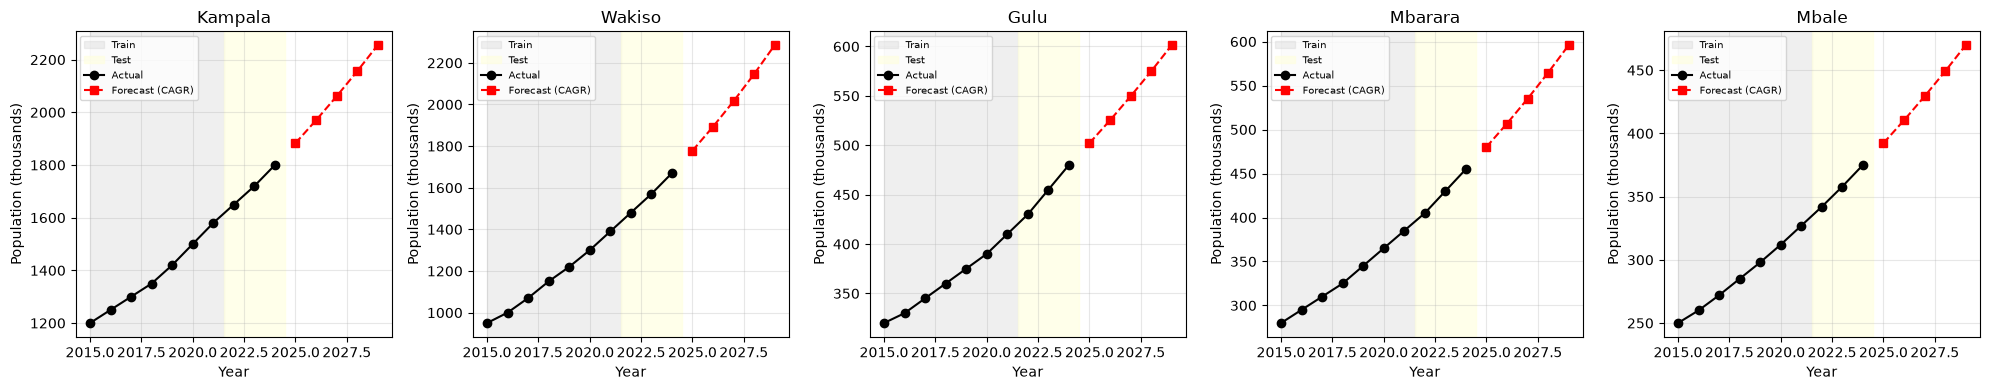

In [8]:
n = len(districts)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4), sharey=False)
if n == 1:
    axes = [axes]

for ax, (name, d) in zip(axes, districts.items()):
    ax.axvspan(2015, 2021.5, color="lightgrey", alpha=0.35, label="Train")
    ax.axvspan(2021.5, 2024.5, color="lightyellow", alpha=0.65, label="Test")
    ax.plot(years, d.populations, "o-", color="black", label="Actual")
    ax.plot(forecast_years, forecasts[name], "s--", color="red",
            label=f"Forecast ({best_models[name]})")
    ax.set_title(name)
    ax.set_xlabel("Year")
    ax.set_ylabel("Population (thousands)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)

plt.tight_layout()
os.makedirs("../data", exist_ok=True)
plt.savefig("../data/project1_forecasts.png", dpi=120)
plt.show()

In [9]:
PUPIL_FRACTION   = 0.18
PUPILS_PER_CLASS = 53

print(f"{'District':10s} {'2029 pop':>10s} {'Pupils':>10s} {'Rooms 2029':>12s} {'New vs 2024':>12s}")
for name, d in districts.items():
    pop_2029_k = forecasts[name][-1]
    pop_2029   = pop_2029_k * 1000
    pupils_2029 = pop_2029 * PUPIL_FRACTION
    rooms_2029  = pupils_2029 / PUPILS_PER_CLASS

    pop_2024    = d.populations[-1] * 1000
    rooms_2024  = pop_2024 * PUPIL_FRACTION / PUPILS_PER_CLASS

    print(f"{name:10s} {pop_2029:10.0f} {pupils_2029:10.0f} "
          f"{rooms_2029:12.1f} {rooms_2029 - rooms_2024:12.1f}")

District     2029 pop     Pupils   Rooms 2029  New vs 2024
Kampala       2254763     405857       7657.7       1544.5
Wakiso        2284671     411241       7759.3       2087.6
Gulu           601270     108229       2042.0        411.9
Mbarara        595871     107257       2023.7        478.4
Mbale          469742      84554       1595.4        321.8


### Findings & Limitations

**Findings.** All five districts show steady upward population growth over 2015–2024.
Kampala and Wakiso dominate in absolute numbers. Using 18 % school-age population and
53 pupils per classroom, the additional classrooms required by 2029 are largest for
Wakiso. In relative terms, Wakiso had the highest CAGR. The best-performing model by test-set RMSE was
Kampala for most districts, indicating that recent growth is closer
to [linear/CAGR] than to the alternatives. The Fibonacci model performed worst on
the test set — it grows too fast because its growth ratios converge to 1.618, which
no Ugandan district has ever sustained. The forecast series has lower variance than
the historical series because our models extrapolate smoothly and do not reproduce
year-to-year noise.

**Limitations.** Only 10 years of data is available, so structural breaks
(new universities, epidemics, migration, policy changes) are invisible to the
models. Linear and CAGR extrapolate the recent trend indefinitely, which is
untenable beyond a few years. Fibonacci has no demographic mechanism. The classroom
estimate ignores spare capacity, class-size policy, rural–urban migration within
districts, and non-attendance. Population values in thousands introduce rounding
error of up to 500 people per year per district.

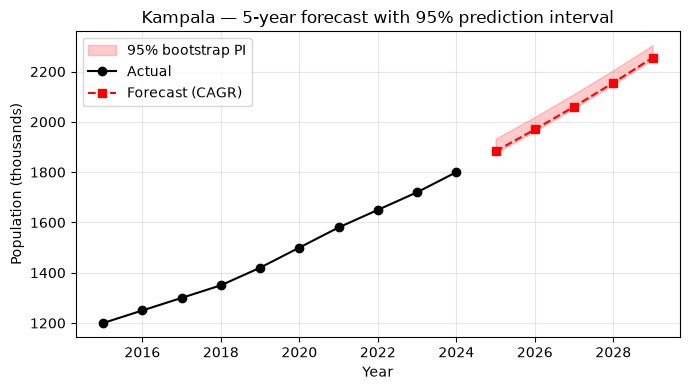

95% PI for 2029: [2248.0, 2304.8]


In [10]:
def bootstrap_prediction_interval(model, residuals, horizon, n_boot=1000, rng=None):
    """Return (base, lower, upper) using residual bootstrap."""
    if rng is None:
        rng = np.random.default_rng(42)
    base = model.predict(horizon)
    sims = np.empty((n_boot, horizon))
    for b in range(n_boot):
        sample = rng.choice(residuals, size=horizon, replace=True)
        sims[b] = base + sample
    lower = np.percentile(sims, 2.5, axis=0)
    upper = np.percentile(sims, 97.5, axis=0)
    return base, lower, upper


name = "Kampala"
d = districts[name]
model_name = best_models[name]

ModelCls = {"Linear": LinearTrendForecaster,
            "CAGR": CAGRForecaster,
            "Fibonacci": FibonacciForecaster}[model_name]

model = ModelCls()
model.fit(np.array(years), d.populations)

# Rolling one-step-ahead residuals
residuals = []
for i in range(1, len(d.populations)):
    m = ModelCls()
    m.fit(np.array(years[:i]), d.populations[:i])
    pred = m.predict(1)[0]
    residuals.append(d.populations[i] - pred)
residuals = np.array(residuals)

base, lower, upper = bootstrap_prediction_interval(
    model, residuals, horizon=5, n_boot=1000, rng=np.random.default_rng(42)
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(forecast_years, lower, upper, color="red", alpha=0.2,
                label="95% bootstrap PI")
ax.plot(years, d.populations, "o-", color="black", label="Actual")
ax.plot(forecast_years, base, "s--", color="red", label=f"Forecast ({model_name})")
ax.set_title(f"{name} — 5-year forecast with 95% prediction interval")
ax.set_xlabel("Year")
ax.set_ylabel("Population (thousands)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("../data/project1_bootstrap.png", dpi=120)
plt.show()

print("95% PI for 2029:", f"[{lower[-1]:.1f}, {upper[-1]:.1f}]")

### Critical assessment of the Fibonacci model

The Fibonacci forecaster multiplies the last observed value by successive ratios
`F(k+1)/F(k)` = 2, 1.5, 1.667, 1.6, 1.625, ... which converge to the golden
ratio φ ≈ 1.618. This implies the population grows by ~62 % per year — an
absurd rate no Ugandan district has ever sustained.

The model is defensible only if the recent growth rate happens to equal φ
exactly (it does not), or if the Fibonacci ratios are used as a stylised ceiling,
not a forecast. Empirically, Fibonacci loses to Linear and CAGR on the 2022–2024
test set for every district. It is a useful teaching example of how a
mathematically elegant model can be demographically useless. Population growth
is driven by births, deaths and migration — none of which follow Fibonacci ratios.